# 🚀 Practice Day 31

**📅 Date:** 2026-10-11  
📁 Category: Phase 1 · 데이터 클리닝 (Round 3/5)

---
# 🎯 Today's Goal
*What am I trying to solve today?*

- Diagnose data quality issues in messy flight booking data (missing values, duplicates, type errors, inconsistent categories, price outliers)
  (지저분한 항공권 예약 데이터의 품질 문제 진단: 결측치·중복행·타입 오류·표기 불일치·가격 이상값)
- Clean the dataset so it's reliable enough to analyze
  (분석 가능한 수준으로 데이터 정제하기)
- Summarize prices by travel class once the data is clean
  (정제 후 등급별 가격 요약하기)

---
# 📂 Dataset

**Dataset Name:** SkyPass 항공권 예약 데이터 (원본, 지저분한 버전) / SkyPass Flight Bookings (Raw)

**Source:** Synthetically generated for practice / 실습을 위해 코드로 생성한 가상 데이터

**Description:** 280 raw flight booking records (single table) across 8 destinations (Tokyo, Paris, New York, Sydney, Bangkok, Dubai, London, Singapore) and 3 travel classes (Economy, Business, First). Prices are in USD. Deliberately includes missing values, exact duplicate rows, a `price` column mixing numbers with junk text, inconsistent capitalization/spacing in `travel_class` and `destination`, and out-of-range price outliers (negative and implausibly high values).
(280건의 항공권 예약 원본 데이터입니다(단일 테이블, 가격은 USD). 8개 목적지(Tokyo/Paris/New York/Sydney/Bangkok/Dubai/London/Singapore), 3개 등급(Economy/Business/First)에 걸쳐 있습니다. 결측치, 완전 중복행, 숫자와 문자가 섞인 price 컬럼, travel_class·destination의 대소문자/공백 표기 불일치, 범위를 벗어난 price 이상값(음수·비현실적 고액)이 의도적으로 섞여 있습니다.)

## Dataset Preview

In [88]:
# Dataset Preview
import pandas as pd
import numpy as np

np.random.seed(42)
pd.set_option('display.float_format', '{:,.2f}'.format)
rng = np.random.default_rng(42)

# --- Generate messy flight booking records ---
n_clean = 265
n_dupe = 15

destinations = ['Tokyo', 'Paris', 'New York', 'Sydney', 'Bangkok', 'Dubai', 'London', 'Singapore']
dest_w = [0.16, 0.13, 0.15, 0.08, 0.14, 0.10, 0.14, 0.10]
base_price = {'Tokyo': 850, 'Paris': 1350, 'New York': 1450, 'Sydney': 1600,
              'Bangkok': 550, 'Dubai': 950, 'London': 1300, 'Singapore': 700}  # USD

classes = ['Economy', 'Business', 'First']
class_w = [0.78, 0.18, 0.04]
class_mult = {'Economy': 1.0, 'Business': 2.8, 'First': 5.2}

dest_choice = rng.choice(destinations, size=n_clean, p=dest_w)
class_choice = rng.choice(classes, size=n_clean, p=class_w)
booking_dates = pd.to_datetime('2024-01-01') + pd.to_timedelta(rng.integers(0, 240, size=n_clean), unit='D')

price = np.array([base_price[d] for d in dest_choice]) * np.array([class_mult[c] for c in class_choice])
price = price * rng.normal(1.0, 0.08, n_clean)
price = price.round().astype(int)  # nearest USD

df = pd.DataFrame({
    'booking_id': [f'BK{str(i).zfill(4)}' for i in range(1, n_clean + 1)],
    'destination': dest_choice,
    'travel_class': class_choice,
    'booking_date': booking_dates,
    'price': price
})
df['destination'] = df['destination'].astype(object)
df['travel_class'] = df['travel_class'].astype(object)
df['price'] = df['price'].astype(object)
df['booking_date'] = df['booking_date'].astype(object)

# --- inject realistic messiness (this is what you'll clean up below) ---

# 1) Inconsistent text formatting: travel_class casing/whitespace
class_variants = {
    'Economy': ['economy', 'ECONOMY', ' Economy', 'Economy '],
    'Business': ['business', 'BUSINESS', ' Business', 'Business '],
    'First': ['first', 'FIRST', ' First', 'First '],
}
mess_idx = rng.choice(df.index, size=int(n_clean * 0.45), replace=False)
for i in mess_idx:
    df.loc[i, 'travel_class'] = rng.choice(class_variants[df.loc[i, 'travel_class']])

# 2) Inconsistent text formatting: destination casing/whitespace
mess_idx2 = rng.choice(df.index, size=int(n_clean * 0.30), replace=False)
for i in mess_idx2:
    base = df.loc[i, 'destination']
    df.loc[i, 'destination'] = rng.choice([base.lower(), base.upper(), ' ' + base, base + ' '])

# 3) price: non-numeric junk values + unrealistic outliers
used_idx = set()
price_junk_vals = ['N/A', 'TBD', 'pending', 'unknown']
junk_idx = rng.choice(df.index, size=10, replace=False)
used_idx.update(junk_idx.tolist())
for j, i in enumerate(junk_idx):
    df.loc[i, 'price'] = price_junk_vals[j % len(price_junk_vals)]

avail = df.index.difference(list(used_idx))
outlier_idx = rng.choice(avail, size=8, replace=False)
used_idx.update(outlier_idx.tolist())
outlier_vals = [-50, -120, 15000, 22000, -8, 18500, -30, 30000]  # USD
for j, i in enumerate(outlier_idx):
    df.loc[i, 'price'] = outlier_vals[j % len(outlier_vals)]

# 4) Missing values scattered across columns
price_avail = df.index.difference(list(used_idx))
df.loc[rng.choice(price_avail, size=9, replace=False), 'price'] = np.nan
for col, n_missing in [('destination', 8), ('travel_class', 7), ('booking_date', 8)]:
    df.loc[rng.choice(df.index, size=n_missing, replace=False), col] = np.nan

# 5) Duplicate rows (simulates a booking-system retry creating duplicate records)
dupe_rows = df.sample(n=n_dupe, random_state=7)
df = pd.concat([df, dupe_rows], ignore_index=True)

# Shuffle so duplicates aren't sitting next to their source row
df = df.sample(frac=1, random_state=99).reset_index(drop=True)

df.head(10)


,booking_id,destination,travel_class,booking_date,price
0,BK0199,Paris,ECONOMY,2024-05-09 00:00:00,1315
1,BK0045,London,Economy,2024-03-14 00:00:00,1430
2,BK0127,New York,Economy,2024-02-04 00:00:00,1490
3,BK0145,Sydney,First,2024-06-05 00:00:00,9516
4,BK0003,London,Economy,2024-02-04 00:00:00,1145
5,BK0203,Sydney,Business,2024-04-16 00:00:00,5163
6,BK0107,Sydney,Economy,2024-01-06 00:00:00,1613
7,BK0187,New York,Business,2024-07-25 00:00:00,NaN
8,BK0016,Paris,Economy,2024-02-09 00:00:00,15000
9,BK0159,Dubai,Economy,2024-07-13 00:00:00,1026


## Dataset Information

In [89]:
# Dataset Information
df.info()
print("\nShape:", df.shape)
df.describe(include='all')


<class 'pandas.DataFrame'>
RangeIndex: 280 entries, 0 to 279
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   booking_id    280 non-null    str   
 1   destination   271 non-null    object
 2   travel_class  272 non-null    object
 3   booking_date  272 non-null    object
 4   price         271 non-null    object
dtypes: object(4), str(1)
memory usage: 11.1+ KB

Shape: (280, 5)


,booking_id,destination,travel_class,booking_date,price
count,280,271,272,272,271
unique,265,38,14,164,235
top,BK0199,Tokyo,Economy,2024-07-23 00:00:00,TBD
freq,2,38,122,5,3


---
# ❓ Business Questions

1. **(Analysis)** How many missing values exist in each column, and how many exact duplicate rows are in the dataset?
   (각 컬럼별 결측치 개수와 완전 중복행의 개수는?)
2. **(Analysis)** How many rows have a non-numeric/invalid `price` value, and what inconsistent formats appear in `travel_class` and `destination`?
   (`price`에서 숫자로 변환되지 않는 값은 몇 건이며, `travel_class`와 `destination`에는 어떤 표기 불일치가 나타나는가?)
3. **(Analysis)** Among valid numeric prices, how many fall outside a realistic range (e.g., negative or implausibly high)?
   (유효한 숫자형 price 중 현실적인 범위를 벗어난 값(음수 또는 비현실적 고액)은 몇 건인가?)
4. **(Visualization)** After cleaning, what is the average price by travel class?
   (정제 후, 등급별 평균 가격은?)
5. **(Visualization)** After cleaning, what does the overall price distribution look like?
   (정제 후, 전체 가격 분포는 어떤 모습인가?)

---
# 🔍 Data Cleaning Check


In [90]:
# Data Cleaning Check — inspect only. Fixes are in Q1–Q3.
# (확인만. 수정은 Q1~Q3)

print("Missing values")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDtypes")
print(df.dtypes)

print("\nColumn names")
print(df.columns.tolist())

obj_cols = df.select_dtypes(include=["object", "string"]).columns
print("\nText columns — unique counts")
print(df[obj_cols].nunique())


Missing values
booking_id      0
destination     9
travel_class    8
booking_date    8
price           9
dtype: int64

Duplicate rows: 15

Dtypes
booking_id         str
destination     object
travel_class    object
booking_date    object
price           object
dtype: object

Column names
['booking_id', 'destination', 'travel_class', 'booking_date', 'price']

Text columns — unique counts
booking_id      265
destination      38
travel_class     14
booking_date    164
price           235
dtype: int64


---
# 📊 Analysis

## Question 1

**Question:** How many missing values exist in each column, and how many exact duplicate rows are in the dataset? (각 컬럼별 결측치 개수와 완전 중복행의 개수는?)

**Result:** Missing values: `destination` **9**, `travel_class` **8**, `booking_date` **8**, `price` **9**, `booking_id` **0**. There are **15** exact duplicate rows.  
(결측치는 destination 9, travel_class 8, booking_date 8, price 9, booking_id 0. 완전 중복행은 15건)

**Insight:** The four columns with gaps hold **34** missing cells in total. `booking_id` has **265** unique values across **280** rows, and the **15** extra rows are the duplicates.  
(결측이 있는 네 컬럼의 빈 칸은 모두 34개. booking_id는 280행에 고유값 265개이고, 나머지 15행이 중복)


In [91]:
# Question 1: missing values per column + exact duplicate row count

print("Missing values\n", df.isnull().sum())

print("\nDuplicate rows: ", df.duplicated().sum())

clean_df = df.drop_duplicates().copy()

Missing values
 booking_id      0
destination     9
travel_class    8
booking_date    8
price           9
dtype: int64

Duplicate rows:  15


## Question 2

**Question:** How many rows have a non-numeric/invalid `price` value, and what inconsistent formats appear in `travel_class` and `destination`? (`price` 무효값 건수와 `travel_class`/`destination` 표기 불일치는?)

**Result:** `price` has **10** text values that `pd.to_numeric` turns into NaN (nulls go from **9** to **19**). `travel_class` has **14** spellings and `destination` has **38**, with mixed case and leading or trailing spaces.  
(price는 숫자로 바꾸면 NaN이 되는 문자값이 10건(널이 9에서 19로 늘어남). travel_class는 표기 14가지, destination은 38가지이고, 대소문자와 앞뒤 공백이 섞여 있음)

**Insight:** After `.str.strip()` and `.str.title()`, `travel_class` is down to **3** values (Economy, Business, First) and `destination` to **8** cities, besides the missing ones.  
(strip과 title 후 결측 외에 travel_class는 3개, destination은 8개 도시로 정리됨)


In [92]:
# Question 2: invalid price values + travel_class/destination formatting inconsistencies

print("travel_class\n", df['travel_class'].unique())
print("destination\n", df['destination'].unique())

clean_df['travel_class'] = clean_df['travel_class'].str.strip()
clean_df['travel_class'] = clean_df['travel_class'].str.title()

clean_df['destination'] = clean_df['destination'].str.strip()
clean_df['destination'] = clean_df['destination'].str.title()

print("After cleaning travel_class\n", clean_df['travel_class'].unique())
print("After cleaning destination\n", clean_df['destination'].unique())

print("price\n", clean_df['price'].isnull().sum())

clean_df['price'] = pd.to_numeric(clean_df['price'], errors='coerce')

print("After cleaning price\n", clean_df['price'].isnull().sum())



travel_class
 [np.str_('ECONOMY') np.str_(' Economy') 'Economy' 'First' 'Business'
 np.str_('Economy ') np.str_('Business ') np.str_(' Business')
 np.str_('economy') np.str_('BUSINESS') np.str_('business') nan
 np.str_('first') np.str_('FIRST') np.str_('First ')]
destination
 ['Paris' 'London' 'New York' 'Sydney' 'Dubai' np.str_('DUBAI')
 np.str_(' New York') np.str_('New York ') np.str_('new york') 'Bangkok'
 np.str_('London ') 'Tokyo' np.str_('london') nan np.str_('tokyo')
 np.str_(' Paris') np.str_('SINGAPORE') np.str_('dubai')
 np.str_('Bangkok ') np.str_('Tokyo ') np.str_('SYDNEY') 'Singapore'
 np.str_('PARIS') np.str_('paris') np.str_(' London') np.str_('TOKYO')
 np.str_('BANGKOK') np.str_(' Singapore') np.str_('Singapore ')
 np.str_('bangkok') np.str_('LONDON') np.str_(' Sydney') np.str_('sydney')
 np.str_('Dubai ') np.str_('singapore') np.str_(' Dubai')
 np.str_(' Bangkok') np.str_('Paris ') np.str_('NEW YORK')]
After cleaning travel_class
 ['Economy' 'First' 'Business' nan]
Af

## Question 3

**Question:** Among valid numeric prices, how many fall outside a realistic range? (유효한 숫자형 price 중 현실적 범위를 벗어난 값은?)

**Result:** Of **246** numeric prices, **4** are negative (**-$120** to **-$8**) and **4** are above **$10,000** (**$15,000**, **$18,500**, **$22,000**, **$30,000**). That is **8** out-of-range values, and all four of the high ones are Economy.  
(숫자형 price 246건 중 음수 4건(-$120~-$8), $10,000 초과 4건($15,000, $18,500, $22,000, $30,000). 범위 밖은 모두 8건이고, 높은 4건은 모두 Economy)

**Insight:** The highest First price is **$9,516**, so the four Economy prices above **$10,000** are not realistic. The mean is **$1,936.43** against a median of **$1,313.00**, a gap of **$623.43** that the outliers pull up. I kept rows from **$0** to **$10,000**, leaving **238** prices.  
(가장 비싼 First가 $9,516이라 $10,000을 넘는 Economy 4건은 비현실적. 평균 $1,936.43이 중앙값 $1,313.00보다 $623.43 높은 것은 이상값이 끌어올린 탓. $0~$10,000 행만 남겨 238건)


In [93]:
# Question 3: unrealistic price values among valid numeric prices
print(clean_df['price'].describe())

display(clean_df[clean_df['price'] < 0])
display(clean_df[clean_df['price'] > 5000].sort_values(by='price', ascending=False))

clean_df = clean_df[(clean_df['price'] >= 0) & (clean_df['price'] <= 10000)]

count      246.00
mean     1,936.43
std      2,895.95
min       -120.00
25%        851.25
50%      1,313.00
75%      1,672.75
max     30,000.00
Name: price, dtype: float64


,booking_id,destination,travel_class,booking_date,price
59,BK0224,Singapore,Economy,2024-07-11 00:00:00,-8.00
60,BK0047,New York,Economy,2024-02-28 00:00:00,-30.00
233,BK0097,New York,Economy,2024-01-29 00:00:00,-50.00
242,BK0170,Singapore,Economy,2024-03-10 00:00:00,-120.00


,booking_id,destination,travel_class,booking_date,price
179,BK0092,Dubai,Economy,2024-05-01 00:00:00,"30,000.00"
100,BK0086,Tokyo,Economy,2024-04-25 00:00:00,"22,000.00"
68,BK0067,Bangkok,Economy,2024-07-23 00:00:00,"18,500.00"
8,BK0016,Paris,Economy,2024-02-09 00:00:00,"15,000.00"
3,BK0145,Sydney,First,2024-06-05 00:00:00,"9,516.00"
158,BK0263,New York,First,2024-05-11 00:00:00,"7,775.00"
232,BK0182,NaN,First,2024-07-05 00:00:00,"6,144.00"
148,BK0192,Paris,First,2024-04-08 00:00:00,"5,519.00"
5,BK0203,Sydney,Business,2024-04-16 00:00:00,"5,163.00"
92,BK0015,Sydney,Business,2024-04-22 00:00:00,"5,078.00"


---
# 📈 Visualization

**Chart 1:** Bar chart — average price by travel class (막대그래프: 등급별 평균 가격)

*Interpretation:* The bars rise from Economy at about **$1,087** to Business at about **$3,151** and First at about **$6,068**. Business is about **$2,064** above Economy, and First is about **$2,916** above Business. The First bar has the longest error line.  
(막대는 Economy 약 $1,087, Business 약 $3,151, First 약 $6,068로 올라감. Business는 Economy보다 약 $2,064, First는 Business보다 약 $2,916 높음. First 막대의 오차선이 가장 김)

---

**Chart 2:** Histogram — distribution of price (히스토그램: 가격 분포)

*Interpretation:* The tallest bars reach **51** and all sit below about **$1,650**. After that the bars drop to single digits and thin out to one price near **$9,516**.  
(가장 높은 막대는 51이고 모두 약 $1,650 아래. 그 뒤로는 한 자릿수로 줄어 $9,516 근처 하나까지 이어지는 오른쪽 꼬리)


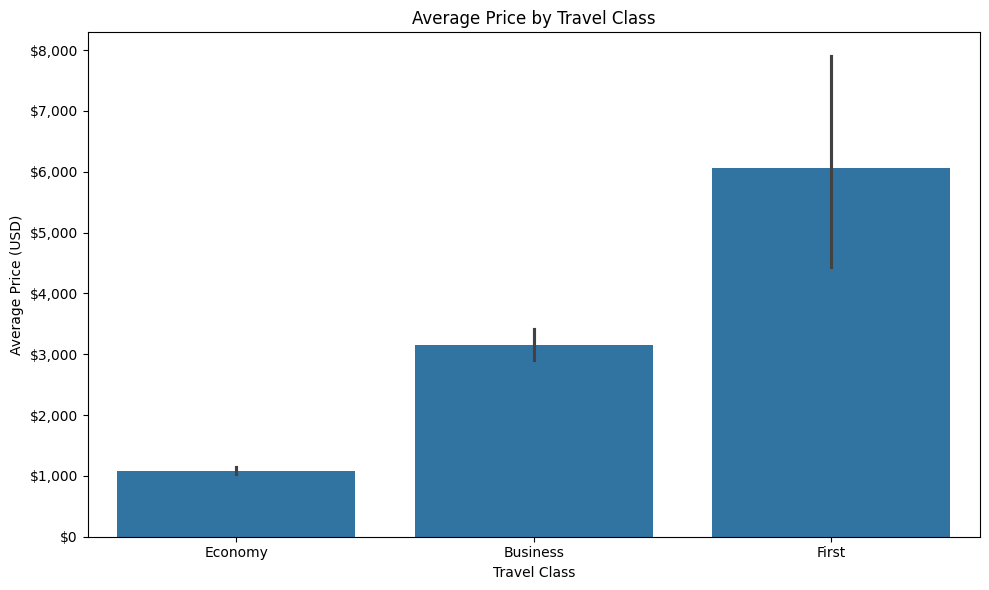

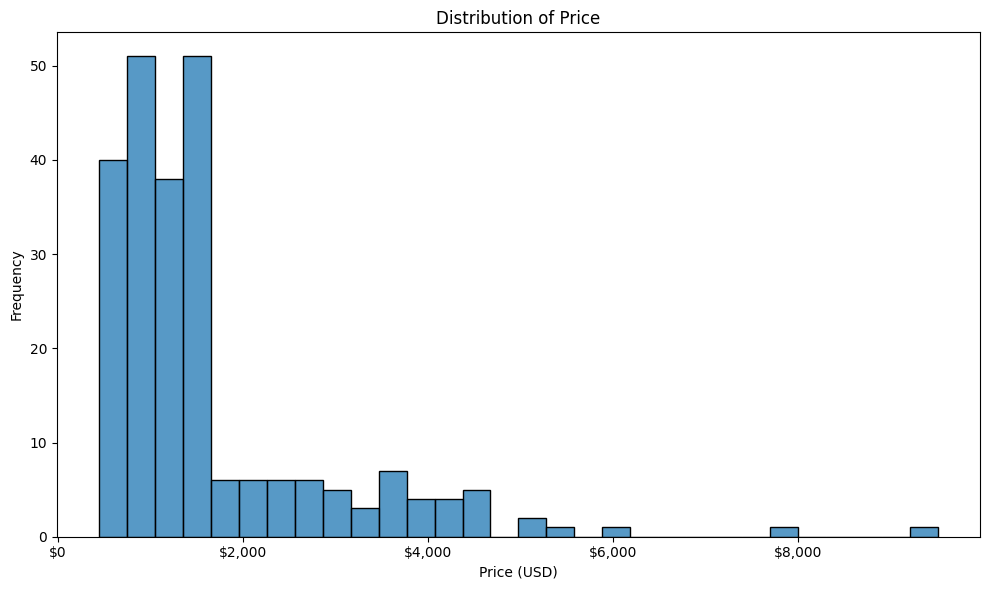

In [94]:
# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Chart 1: average price by travel_class (bar chart)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x='travel_class', y='price', data=clean_df, order=['Economy', 'Business', 'First'], ax=ax)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Average Price by Travel Class')
ax.set_xlabel('Travel Class')
ax.set_ylabel('Average Price (USD)')
plt.tight_layout()
plt.show()

# Chart 2: distribution of price (histogram)

fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(clean_df['price'], bins=30, ax=ax)
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Distribution of Price')
ax.set_xlabel('Price (USD)')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

---
# 💼 Business Insights
*What did I discover?*

- **15** of **280** booking rows are exact duplicates, and the four columns with gaps hold **34** missing cells.  
  (280행 중 15행이 완전 중복이고, 결측이 있는 네 컬럼의 빈 칸은 34개)
- `price` has **10** text values and **8** out-of-range numbers (**4** negative, **4** Economy above **$10,000**).  
  (price에는 문자값 10건과 범위 밖 숫자 8건(음수 4건, $10,000 초과 Economy 4건)이 있음)
- After cleaning, average price rises from Economy (about **$1,087**) to Business (about **$3,151**) to First (about **$6,068**).  
  (정제 후 평균 가격은 Economy 약 $1,087, Business 약 $3,151, First 약 $6,068로 올라감)  


---
# 🎯 Business Recommendation
*If I were the Business Analyst...*

1. Check why the booking system saves the same booking twice, since **15** of **280** rows were duplicates.  
   (예약 시스템이 같은 예약을 두 번 저장하는 이유를 확인하기. 280행 중 15행이 중복이었음)
2. Reject negative and text values when `price` is entered. The data had **4** negative values and **10** text values.  
   (price 입력 시 음수와 문자값을 막기. 데이터에 음수 4건, 문자값 10건이 있었음)
3. Use fixed choices for `travel_class` and `destination`. Free text produced **14** spellings of 3 classes and **38** of 8 cities.  
   (travel_class와 destination은 고정 선택지로 받기. 자유 입력이 3개 등급을 14가지, 8개 도시를 38가지로 적게 만듦)  


---
# ❌ Mistakes
*What mistakes did I make today?*

- I expected the rows from `df[df.duplicated()]` to match each other. They did not, because `duplicated()` hides the first copy and shows only the extra ones.  
  (`df[df.duplicated()]`의 행끼리 서로 같을 거라 생각함. duplicated()는 첫 번째 복사본은 빼고 추가분만 보여줌)
- Q1 counted **15** duplicates, but `clean_df` still kept them, so a booking would be counted twice in the charts.  
  (Q1에서 중복 15건을 셌지만 clean_df에는 남아 있어서 차트에서 같은 예약이 두 번 들어갈 뻔함)
- I left the negative prices and the Economy prices above **$10,000** in the table. They would stretch Chart 2 out to **$30,000**.  
  (음수 가격과 $10,000 넘는 Economy를 표에 남겨 둠. 그대로면 차트 2가 $30,000까지 늘어남)  


---
# ✅ What I Learned
*Today's biggest lesson*

- `df.duplicated()` uses `keep='first'` by default. Use `keep=False` to see both copies, and `drop_duplicates()` to remove the extras.  
  (duplicated()는 기본이 keep='first'. 두 복사본을 같이 보려면 keep=False, 추가분 제거는 drop_duplicates())
- `pd.to_numeric(..., errors='coerce')` turns text into NaN, so comparing null counts before and after gives the number of text values.  
  (to_numeric(errors='coerce')는 문자를 NaN으로 바꿈. 전후 널 수를 비교하면 문자값 건수가 나옴)
- Judge outliers against the other classes, then filter by a price range before charting. `pd.set_option('display.float_format', ...)` also makes `describe()` readable.  
  (이상값은 다른 등급 가격과 비교해 판단하고, 차트 전에 가격 범위로 거름. display.float_format은 describe()를 읽기 좋게 만듦)  


---
# 🧠 Reflection

**What was difficult?**  
Reading the `duplicated()` output and deciding which prices were outliers.  
(duplicated() 결과를 읽는 것과 어떤 가격이 이상값인지 정하는 것)

**Why?**  
The rows on screen looked unrelated because their first copies were hidden, and First and Business prices were also high but still valid.  
(첫 번째 복사본이 빠져서 화면의 행들이 서로 무관해 보였고, First와 Business도 가격이 높지만 정상 값이었음)

**How did I solve it?**  
Learned that `keep='first'` shows only the extras, and compared the high prices with the First maximum of **$9,516**.  
(keep='first'는 추가분만 보여준다는 것을 알았고, 높은 가격을 First 최고가 $9,516과 비교함)

**What would I do differently next time?**  
Look at `keep=False` first, and set the outlier cutoff by travel class before filtering.  
(먼저 keep=False로 보고, 필터 전에 등급별로 이상값 기준을 정하기)


---
# ⭐ Self Evaluation

**Understanding**  
★★★★★★★☆☆☆  
Duplicates, text prices, spelling fixes, and the outlier filter are clear. Choosing the cutoff by class still needs practice.  
(중복, 문자 가격, 표기 정리, 이상값 필터는 이해함. 등급별 기준을 정하는 것은 연습이 더 필요함)

**Confidence**  
★★★★★★☆☆☆☆  

**Difficulty**  
★★★★★☆☆☆☆☆  
The pandas steps were short. The hard part was judging what counts as an outlier.  
(pandas 단계는 짧았고, 어려운 부분은 무엇이 이상값인지 판단하는 것이었음)


---
# 📌 Tomorrow
*Tomorrow I will learn:*

- Practice Day 32 — visualization basics (Round 3/5)  
  (시각화 기초 복습)  
